In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import STL

from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().resolve().parent))

print(sys.executable)

ok
/Users/yuanxinyi/Desktop/panel-forcast-kit/.venv/bin/python


In [2]:
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "train.csv").exists()),
    Path.cwd(),
)
csv_path = project_root / "data" / "raw" / "train.csv"

df = pd.read_csv(
    csv_path,
    parse_dates=["date"],
) 

# Trend vs. Time

Total Sales vs. Date, Weekend, Seasonality, etc

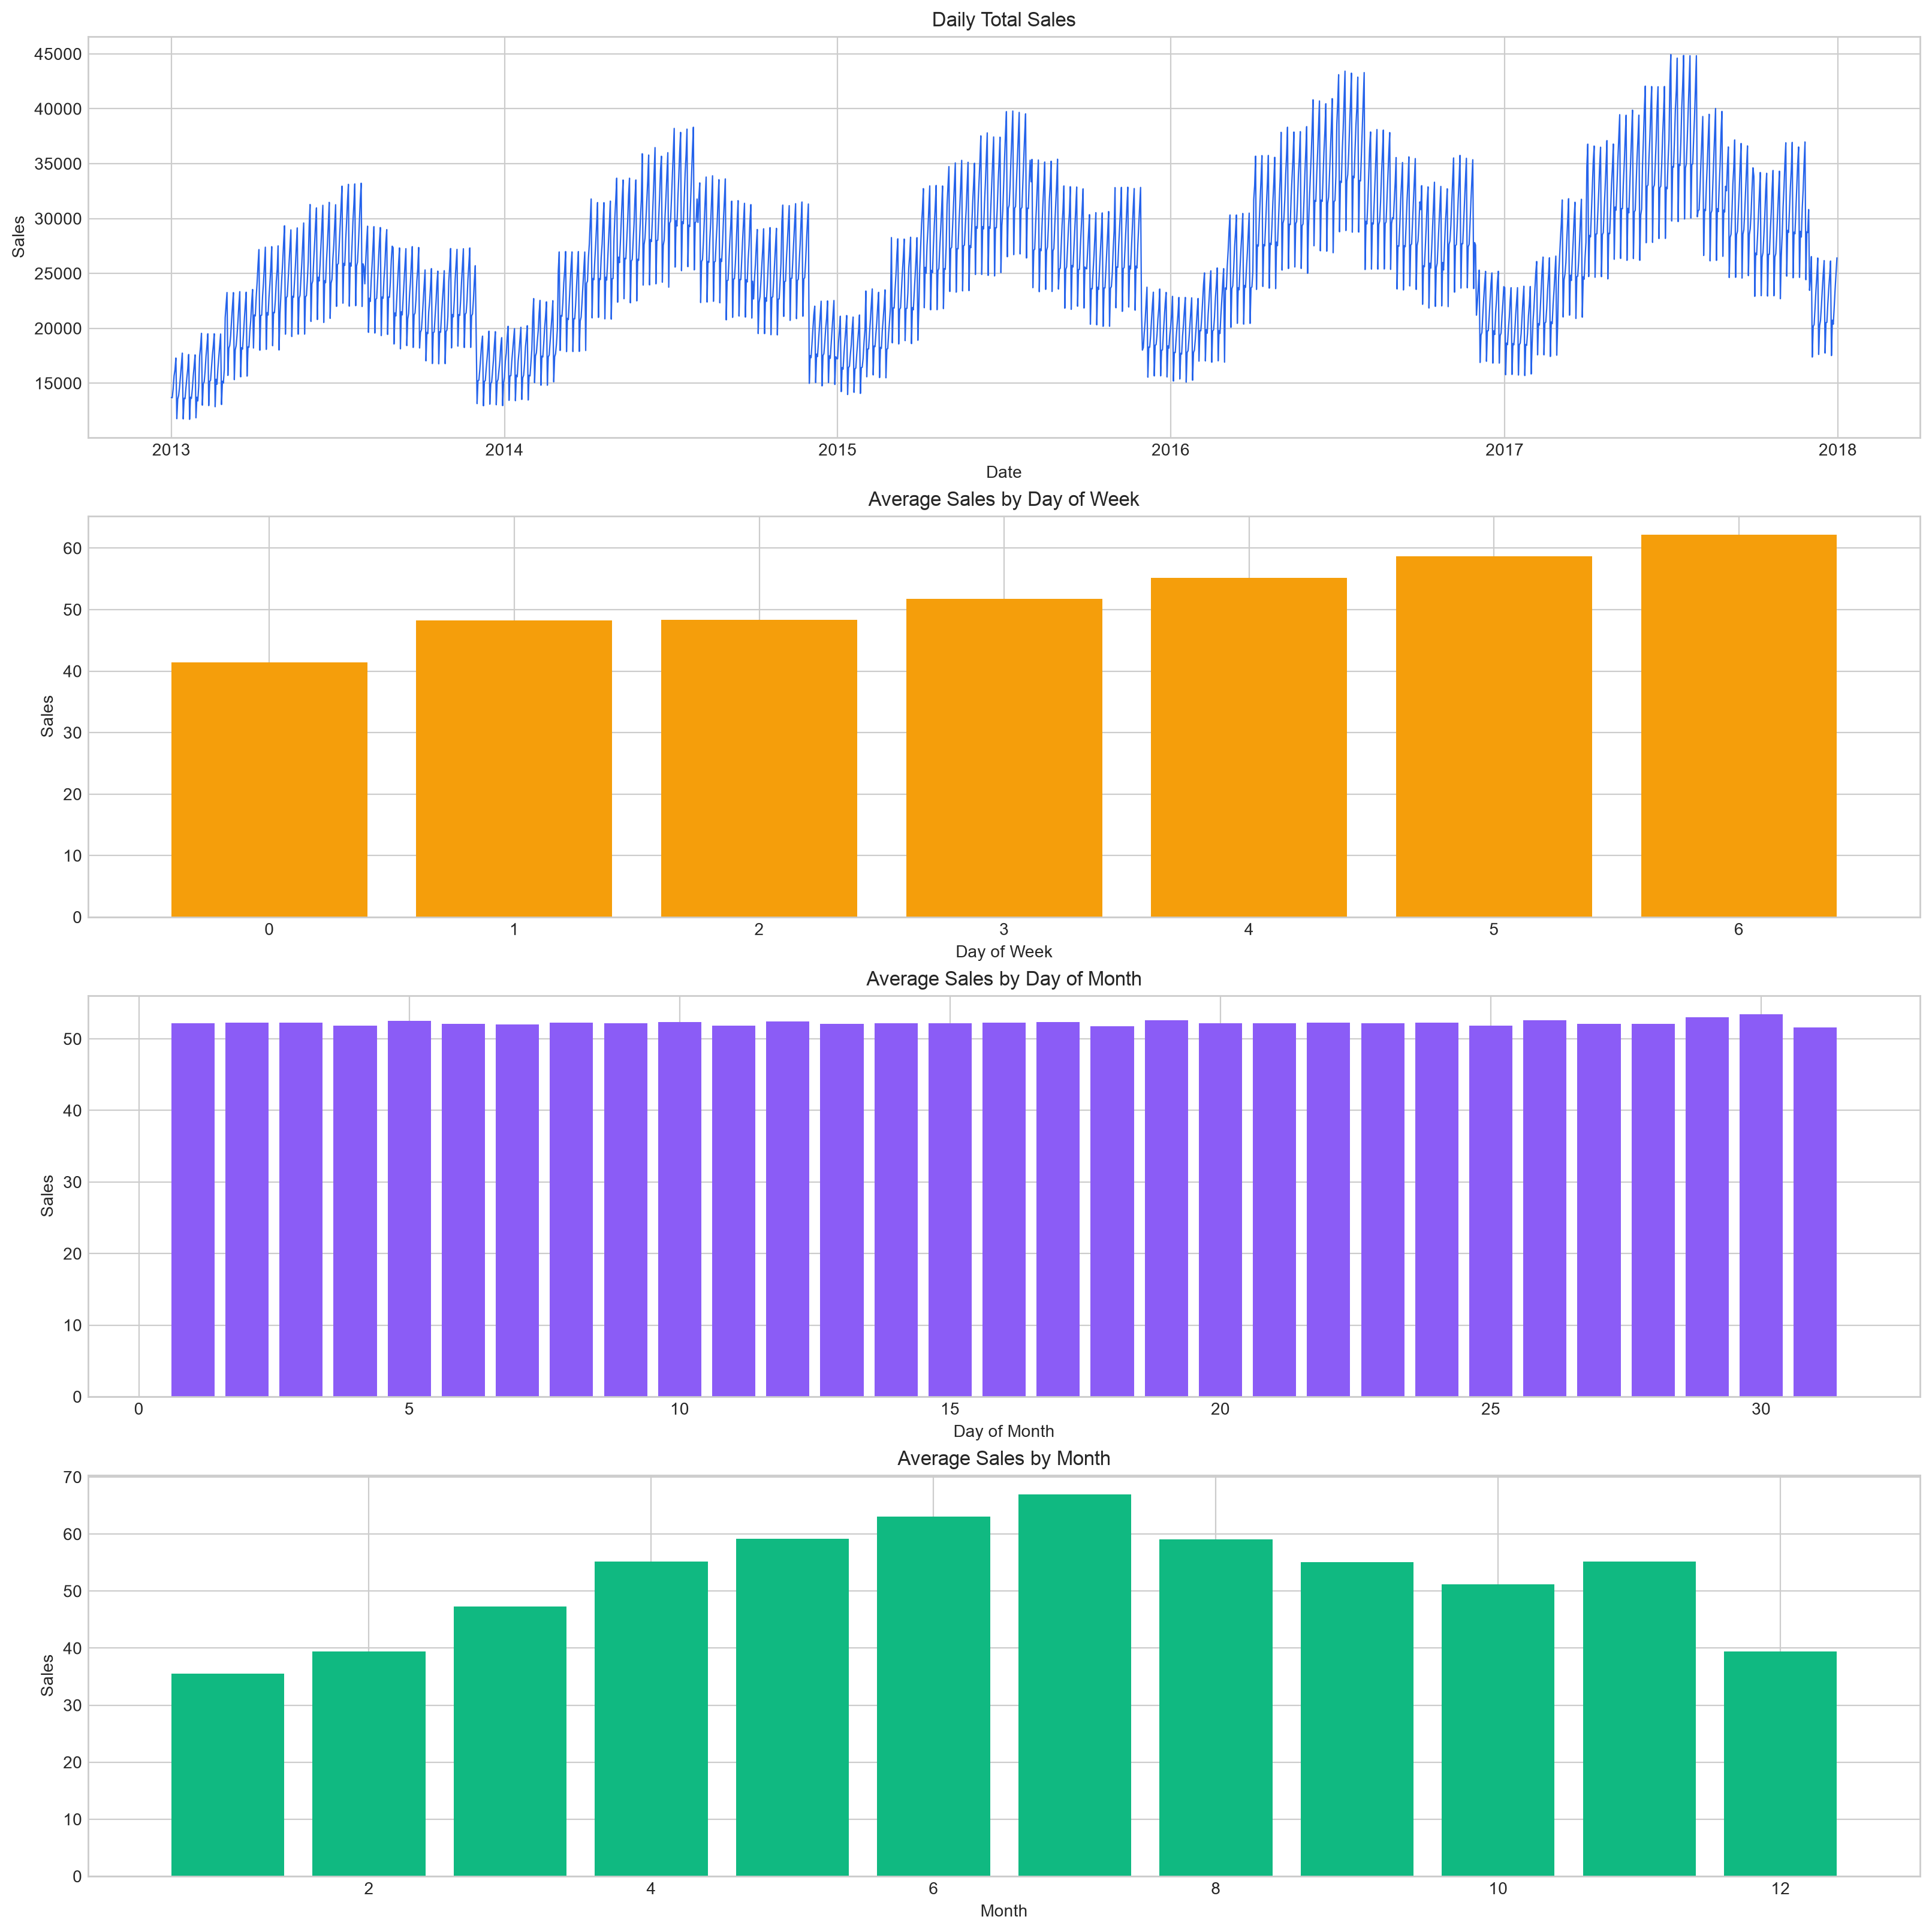

In [ ]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek  # 0=Mon, 6=Sun

# 1) overall sales trend
daily_total = df.groupby("date")["sales"].sum()
# 2) average sales by day of week 
dow_sales = df.groupby("dayofweek")["sales"].mean().sort_index()
# 3) average sales by day of month
day_sales = df.groupby("day")["sales"].mean().sort_index()
# 4) average sales by month
month_sales = df.groupby("month")["sales"].mean().sort_index()

plt.style.use("seaborn-v0_8-whitegrid")

# 每个子图: (数据, 图类型, 标题, x轴标签, 颜色)
plots = [
    (daily_total, "line", "Average Daily Total Sales",           "Date",         "#2563EB"),
    (dow_sales,   "bar",  "Average Sales by Day of Week", "Day of Week",  "#F59E0B"),
    (day_sales,   "bar",  "Average Sales by Day of Month", "Day of Month", "#8B5CF6"),
    (month_sales, "bar",  "Average Sales by Month",       "Month",        "#10B981"),
]

fig, axes = plt.subplots(len(plots), 1, figsize=(16, 16), dpi=200, constrained_layout=True)

for ax, (data, kind, title, xlabel, color) in zip(axes, plots):
    if kind == "line":
        ax.plot(data.index, data.values, linewidth=0.8, color=color)
    else:
        ax.bar(data.index, data.values, color=color)
    ax.set(title=title, xlabel=xlabel, ylabel="Sales", facecolor="#FFFFFF")

plt.show()

In [25]:
dow_avg = df.groupby("dayofweek")["sales"].mean()

monday = dow_avg[0]
for i, day in enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]):
    pct = (dow_avg[i] - monday) / monday * 100
    print(f"{day}: {dow_avg[i]:.1f}  (vs. Monday: {pct:+.1f}%)")

print(f"\nWeekend (Saturday–Sunday) average: {dow_avg[[5, 6]].mean():.1f}")
print(f"Weekday (Monday–Friday) average: {dow_avg[[0, 1, 2, 3, 4]].mean():.1f}")
print(
    f"Weekend is {((dow_avg[[5, 6]].mean() - dow_avg[[0, 1, 2, 3, 4]].mean()) / dow_avg[[0, 1, 2, 3, 4]].mean() * 100):+.1f}% "
    f"higher than weekday"
)

Mon: 41.4  (vs. Monday: +0.0%)
Tue: 48.2  (vs. Monday: +16.4%)
Wed: 48.4  (vs. Monday: +16.7%)
Thu: 51.7  (vs. Monday: +24.8%)
Fri: 55.2  (vs. Monday: +33.1%)
Sat: 58.7  (vs. Monday: +41.6%)
Sun: 62.1  (vs. Monday: +50.0%)

Weekend (Saturday–Sunday) average: 60.4
Weekday (Monday–Friday) average: 49.0
Weekend is +23.3% higher than weekday


In [30]:
dow_avg = df.groupby("month")["sales"].mean()

january = dow_avg[1]
for i, month in enumerate(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], start=1):
    pct = (dow_avg[i] - january) / january * 100
    print(f"{month}: {dow_avg[i]:.1f}  (vs. January: {pct:+.1f}%)")

print(f"\nQ1 average: {dow_avg[[1, 2, 3]].mean():.1f}")
print(f"Q2 average: {dow_avg[[4, 5, 6]].mean():.1f}")
print(f"Q3 average: {dow_avg[[7, 8, 9]].mean():.1f}")
print(f"Q4 average: {dow_avg[[10, 11, 12]].mean():.1f}")


Jan: 35.5  (vs. January: +0.0%)
Feb: 39.4  (vs. January: +10.8%)
Mar: 47.3  (vs. January: +33.2%)
Apr: 55.2  (vs. January: +55.3%)
May: 59.1  (vs. January: +66.4%)
Jun: 63.0  (vs. January: +77.4%)
Jul: 67.0  (vs. January: +88.6%)
Aug: 59.1  (vs. January: +66.4%)
Sep: 55.1  (vs. January: +55.0%)
Oct: 51.2  (vs. January: +44.1%)
Nov: 55.2  (vs. January: +55.4%)
Dec: 39.4  (vs. January: +10.8%)

Q1 average: 40.7
Q2 average: 59.1
Q3 average: 60.4
Q4 average: 48.6


In [40]:
'''
base = stats[2013]   # 以 2013 为基准
print("=== 各年:平均水平、绝对波动、相对波动率(CV),均较 2013 ===")
for y in sorted(stats):
    s = stats[y]
    mean_pct = (s["mean"] - base["mean"]) / base["mean"] * 100
    std_pct  = (s["std"]  - base["std"])  / base["std"]  * 100
    cv_pct   = (s["cv"]   - base["cv"])   / base["cv"]   * 100
    print(f"{y}: 均值 {s['mean']:7.0f} ({mean_pct:+6.1f}%) | "
          f"标准差 {s['std']:6.0f} ({std_pct:+6.1f}%) | "
          f"CV {s['cv']:.3f} ({cv_pct:+6.1f}%)")'''

daily = df.groupby("date")["sales"].sum().sort_index() 
# 按天把销量聚合，对每一天的销量求和，结果会变成一个按日期索引的Series，按索引排序，让日期从早到晚按时间顺序排列，
# 在这里去掉门店和item自由度/or say 把它们积分（聚合）掉，把问题降到时间维度上来观察

daily_df = daily.to_frame("sales") 
# daily 目前是一个 Series，也就是一列数据，索引是日期
# to_frame("sales") 把它转换成 DataFrame，并把这一列命名为 sales
daily_df["year"] = daily_df.index.year
# 从日期索引里取年份
# 把它作为一列新增到 DataFrame里，方便后面做group

print("=== 各年:平均水平、绝对波动、相对波动率(CV) ===")
prev_cv = None
stats = {}
for y, g in daily_df.groupby("year"):
    # daily_df.groupby("year")：按 year 列分组
    # for y, g in ...：对每一个组都循环一次
    # y 是年份，g 是该年份对应的子 DataFrame
    stats[y] = {
        "mean": g["sales"].mean(),
        "std":  g["sales"].std(),
        "cv":   g["sales"].std() / g["sales"].mean(),
    }
    mean = stats[y]["mean"]
    std = stats[y]["std"]
    cv   = stats[y]["cv"]
    trend = "" if prev_cv is None else f"  (较上年 {'↑' if cv>prev_cv else '↓'} {(cv-prev_cv)/prev_cv*100:+.1f}%)"
    print(f"{y}: 均值 {mean:7.0f} | 标准差(绝对波动) {std:6.0f} | CV(相对波动率) {cv:.3f}{trend}")
    prev_cv = cv

=== 各年:平均水平、绝对波动、相对波动率(CV) ===
2013: 均值   21757 | 标准差(绝对波动)   4841 | CV(相对波动率) 0.223
2014: 均值   25029 | 标准差(绝对波动)   5588 | CV(相对波动率) 0.223  (较上年 ↑ +0.3%)
2015: 均值   26128 | 标准差(绝对波动)   5816 | CV(相对波动率) 0.223  (较上年 ↓ -0.3%)
2016: 均值   28298 | 标准差(绝对波动)   6294 | CV(相对波动率) 0.222  (较上年 ↓ -0.1%)
2017: 均值   29408 | 标准差(绝对波动)   6514 | CV(相对波动率) 0.222  (较上年 ↓ -0.4%)


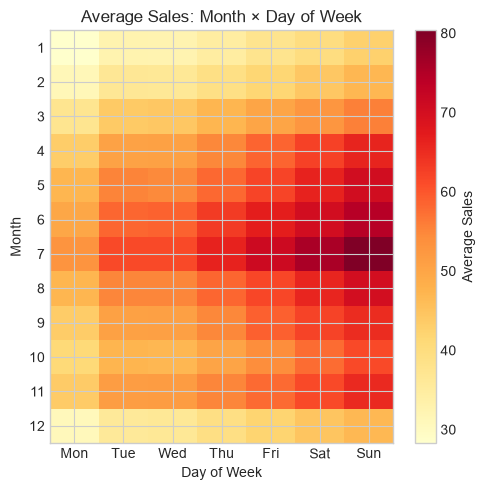

In [41]:
pivot = df.pivot_table(index="month", columns="dayofweek", values="sales", aggfunc="mean")
pivot.columns = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

plt.figure(figsize=(5, 5))
plt.imshow(pivot, aspect="auto", cmap="YlOrRd")
plt.colorbar(label="Average Sales")
plt.xticks(range(7), ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
plt.yticks(range(12), range(1, 13))
plt.xlabel("Day of Week")
plt.ylabel("Month")
plt.title("Average Sales: Month × Day of Week")
plt.tight_layout()
plt.show()


# Trend vs. Store/Item

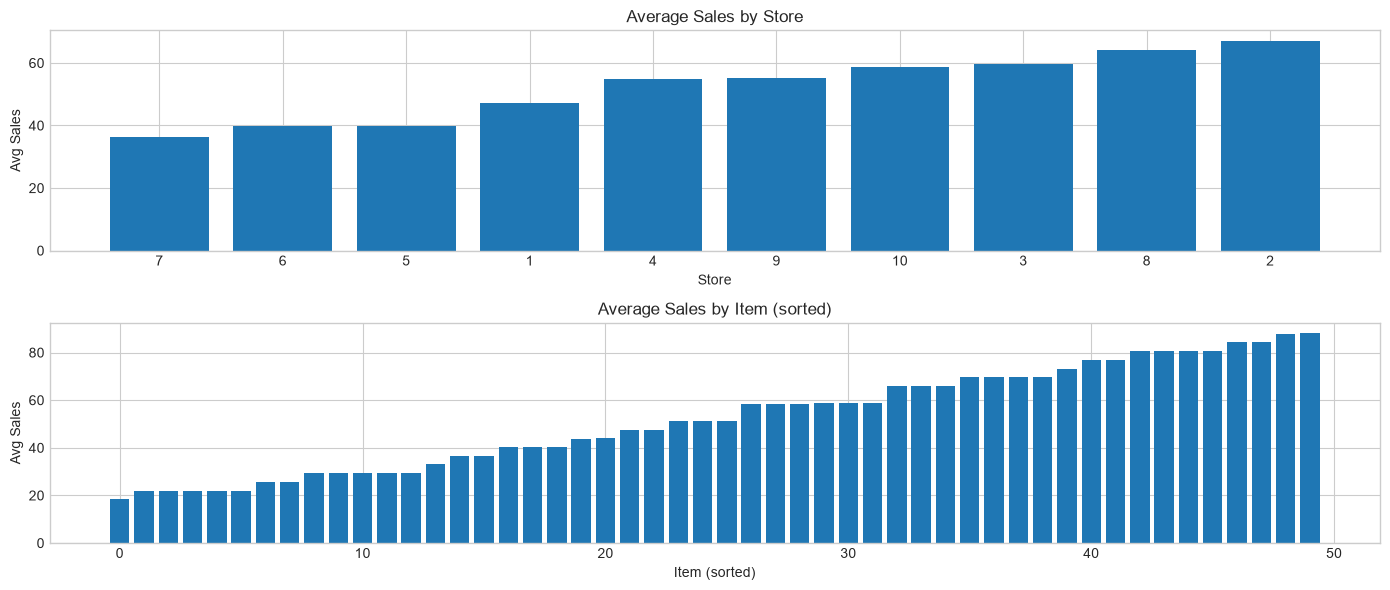

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

store_avg = df.groupby("store")["sales"].mean().sort_values()
axes[0].bar(store_avg.index.astype(str), store_avg.values)
axes[0].set_title("Average Sales by Store")
axes[0].set_xlabel("Store"); axes[0].set_ylabel("Avg Sales")

item_avg = df.groupby("item")["sales"].mean().sort_values()
axes[1].bar(range(len(item_avg)), item_avg.values)
axes[1].set_title("Average Sales by Item (sorted)")
axes[1].set_xlabel("Item (sorted)"); axes[1].set_ylabel("Avg Sales")

plt.tight_layout()
plt.show()

In [43]:
# Quantitative analysis: examine additional summary statistics
store_avg = df.groupby("store")["sales"].mean().sort_values()
baseline_store = store_avg.iloc[0]   # Lowest-performing store

print("=== Daily average sales by store (sorted from low to high) and relative deviation from the lowest store ===")
for store_id, avg in store_avg.items():
    pct = (avg - baseline_store) / baseline_store * 100
    print(f"Store {store_id:2d}: {avg:5.1f}  (+{pct:5.1f}%)")

print(f"\nHighest store / lowest store ratio: {store_avg.iloc[-1] / store_avg.iloc[0]:.2f}x")
print(f"Maximum deviation: Store {store_avg.index[-1]} is {(store_avg.iloc[-1]-baseline_store)/baseline_store*100:.1f}% higher than the lowest store")

# ===== Item analysis: distributional pattern =====
item_avg = df.groupby("item")["sales"].mean().sort_values()

print("\n=== Distribution of average daily sales by item ===")
print(f"Lowest-selling item: {item_avg.iloc[0]:.1f}")
print(f"Highest-selling item: {item_avg.iloc[-1]:.1f}")
print(f"Highest / lowest ratio: {item_avg.iloc[-1]/item_avg.iloc[0]:.2f}x")
print(f"Median: {item_avg.median():.1f}")
print(f"Mean:   {item_avg.mean():.1f}")
print(f"\nMean vs median difference (to assess skewness): mean - median = {item_avg.mean()-item_avg.median():.2f}")

# Concentration: proportion of total sales accounted for by the top few items
total = item_avg.sum()
top10pct_n = max(1, int(len(item_avg)*0.1))
top20pct_n = max(1, int(len(item_avg)*0.2))
print(f"\nTop {top10pct_n} items (top 10%) account for {item_avg.iloc[-top10pct_n:].sum()/total*100:.1f}% of total sales")
print(f"Top {top20pct_n} items (top 20%) account for {item_avg.iloc[-top20pct_n:].sum()/total*100:.1f}% of total sales")

=== Daily average sales by store (sorted from low to high) and relative deviation from the lowest store ===
Store  7:  36.4  (+  0.0%)
Store  6:  39.7  (+  9.3%)
Store  5:  39.8  (+  9.4%)
Store  1:  47.3  (+ 30.0%)
Store  4:  54.9  (+ 51.0%)
Store  9:  55.0  (+ 51.4%)
Store 10:  58.7  (+ 61.5%)
Store  3:  59.5  (+ 63.7%)
Store  8:  64.1  (+ 76.4%)
Store  2:  67.0  (+ 84.3%)

Highest store / lowest store ratio: 1.84x
Maximum deviation: Store 2 is 84.3% higher than the lowest store

=== Distribution of average daily sales by item ===
Lowest-selling item: 18.4
Highest-selling item: 88.0
Highest / lowest ratio: 4.80x
Median: 51.4
Mean:   52.3

Mean vs median difference (to assess skewness): mean - median = 0.88

Top 5 items (top 10%) account for 16.3% of total sales
Top 10 items (top 20%) account for 31.4% of total sales


In [46]:
holiday_dates = pd.to_datetime([
    "2013-01-01", "2014-01-01", "2015-01-01", "2016-01-01", "2017-01-01",
    "2013-12-25", "2014-12-25", "2015-12-25", "2016-12-25", "2017-12-25"
])

# Keep only these dates
holiday_df = df[df["date"].isin(holiday_dates)].copy()

# Aggregate total sales across these dates
holiday_sales = (
    holiday_df.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
    .rename(columns={"sales": "total_sales"})
)

holiday_sales["day_name"] = holiday_sales["date"].dt.day_name()

print("=== Sales on these holiday dates ===")
print(holiday_sales[["date", "day_name", "total_sales"]])

print(f"\nAverage total sales on these dates: {holiday_sales['total_sales'].mean():.2f}")
print(f"Total sales on these dates: {holiday_sales['total_sales'].sum():.2f}")

for d in holiday_dates:
    before = df[df["date"] == d - pd.Timedelta(days=1)]["sales"].sum()
    after = df[df["date"] == d + pd.Timedelta(days=1)]["sales"].sum()
    avg_2day = (before + after) / 2
    print(d.date(), "Average sales 1 day before and after =", avg_2day)

=== Sales on these holiday dates ===
        date   day_name  total_sales
0 2013-01-01    Tuesday        13696
1 2013-12-25  Wednesday        15351
2 2014-01-01  Wednesday        15556
3 2014-12-25   Thursday        18607
4 2015-01-01   Thursday        17226
5 2015-12-25     Friday        20877
6 2016-01-01     Friday        20158
7 2016-12-25     Sunday        25195
8 2017-01-01     Sunday        23709
9 2017-12-25     Monday        17517

Average total sales on these dates: 18789.20
Total sales on these dates: 187892.00
2013-01-01 Average sales 1 day before and after = 6839.0
2014-01-01 Average sales 1 day before and after = 16038.5
2015-01-01 Average sales 1 day before and after = 17978.5
2016-01-01 Average sales 1 day before and after = 20328.5
2017-01-01 Average sales 1 day before and after = 19782.0
2013-12-25 Average sales 1 day before and after = 15670.0
2014-12-25 Average sales 1 day before and after = 18576.5
2015-12-25 Average sales 1 day before and after = 20923.5
2016-12-2

# Conclusion

1. month, is weekend matter the most 
2. is holiday could be a feature, I'm not sure
3. store and item could matter